In [2]:
import re
import xarray as xr
import numpy as np

from pathlib import Path

from datetime import date, timedelta

import sys


REPO_ROOT = Path.cwd().resolve().parents[2]
SRC = REPO_ROOT / 'src'
if not SRC.is_dir():
    raise RuntimeError(f'Missing source tree: {SRC}')
sys.path.insert(0, str(SRC))

from modules.fireRisk.fwi import statistic
from modules.fireRisk.fwi.utils import write_netcdf

monthly=xr.open_dataset('/Users/kris/Downloads/monthly_lead_03.nc')


## Try calculating $\hat{Y_{t,k}}$


In [3]:
pool_retro=monthly['retro_fwi']

observed_all = statistic.calculate_probabilities(
    hcst=pool_retro,
    fcst=pool_retro.expand_dims(ensemble=[0]),
    climatology_dims=['year'],
    mask_zeros=False,
)

observed_all=observed_all.where(
    np.isfinite(pool_retro)
)

obs_prob=observed_all.sel(year=2017, drop=False)
obs_prob.sel(
    {'y': 200, 'x': 300}
)


 Computing probabilities...


/Users/kris/miniconda3/envs/analytics/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


 Category=0
 Category=1
 Category=2


<xarray.DataArray 'retro_fwi' (category: 3)> Size: 24B
array([0., 1., 0.])
Coordinates:
  * category  (category) int64 24B 0 1 2
    y         int64 8B 200
    x         int64 8B 300
    year      int64 8B 2017
    lat       float32 4B -10.98
    lon       float32 4B -66.97
Attributes:
    long_name:  Fire Weather Index
    units:      1

## Try calculating $\hat{P_{t,k}}$


In [9]:
present=monthly['member_present']==1
pooled_fcst=monthly[f'fcst_fwi'].where(present) 

year=2017

active_ensemble=monthly['ensemble'].values[
    present.sel(year=year).values
]

active_fcst=(
    monthly[f'fcst_fwi']
    .sel(year=year, drop=True)
    .sel(ensemble=active_ensemble)
)

fcst_prob=statistic.calculate_probabilities(
    hcst=pooled_fcst,
    fcst=active_fcst,
    climatology_dims=('year', 'ensemble'),
    mask_zeros=False,
)

fcst_prob.sel(
    {'y': 200, 'x': 300}
)


 Computing probabilities...


/Users/kris/miniconda3/envs/analytics/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


 Category=0
 Category=1
 Category=2


<xarray.DataArray 'fcst_fwi' (category: 3)> Size: 24B
array([0.28571429, 0.42857143, 0.28571429])
Coordinates:
  * category  (category) int64 24B 0 1 2
    y         int64 8B 200
    x         int64 8B 300
    lat       float32 4B -10.98
    lon       float32 4B -66.97
Attributes:
    long_name:  Fire Weather Index
    units:      1

## Find $RPS$ and $RPSS$

Now as we discussed, in order to find `rps` and `rpss_d` I will use the accumulated probabilites vector for $\hat{P}_{t,k}$ and $\hat{Y}_{t,k}$.


In [57]:
fcst_prob, obs_prob=xr.align(fcst_prob, obs_prob, join='exact')

valid=(
    np.isfinite(active_fcst).all('ensemble') &
    np.isfinite(pooled_fcst).any(('year', 'ensemble')) &
    np.isfinite(obs_prob).all('category')
)

In [ ]:
obs_cdf=obs_prob.cumsum('category', skipna=False)

obs_cdf.sel(
    {'y': 200, 'x': 300}
)

<xarray.DataArray 'retro_fwi' (category: 3)> Size: 24B
array([0., 1., 1.])
Coordinates:
  * category  (category) int64 24B 0 1 2
    y         int64 8B 200
    x         int64 8B 300
    year      int64 8B 2017
    lat       float32 4B -10.98
    lon       float32 4B -66.97
Attributes:
    long_name:  Fire Weather Index
    units:      1

In [ ]:
fcst_cdf=fcst_prob.cumsum('category', skipna=False)

fcst_cdf.sel(
    {'y': 200, 'x': 300}
)


<xarray.DataArray 'fcst_fwi' (category: 3)> Size: 24B
array([0.28571429, 0.71428571, 1.        ])
Coordinates:
  * category  (category) int64 24B 0 1 2
    y         int64 8B 200
    x         int64 8B 300
    lat       float32 4B -10.98
    lon       float32 4B -66.97
Attributes:
    long_name:  Fire Weather Index
    units:      1

In [60]:
sum_cat_brier=(
    (fcst_cdf - obs_cdf)**2
).sum(dim='category', skipna=True).where(valid)

sum_cat_brier.sel(
    {'y': 200, 'x': 300}
)

<xarray.DataArray ()> Size: 8B
array(0.16326531)
Coordinates:
    y        int64 8B 200
    x        int64 8B 300
    lat      float32 4B -10.98
    lon      float32 4B -66.97
    year     int64 8B 2017
Attributes:
    long_name:  Fire Weather Index
    units:      1

Let us pause for a bit, and work through the math by hands. In order to find the two `_cdf` variables, we start with the two probabilities vectors.

The `obs_prob`:

```python
array([0., 1., 0.])
```

The `fcst_prob`:

```python
array([0.28571429, 0.42857143, 0.28571429])
```

Both are 1 by 3 in shape, and to find `_cdf` we add each entry's previous entry to itself. [ Enventually all add up to one since they are probability]

1. `obs_cdf = array([0., 1., 1.)`
2. `fcst_cdf = array([2/7, 5/7, 1.])`


Subtract `obs_cdf` for each category from `fcst_cdf`, then square the difference and sum them up in the end.

$$
\text{cummulative birer score} = \left(\frac{2}{7} - 0 \right)^2 + \left(\frac{5}{7} - 1 \right)^2 + \left(1. - 1. \right)^2\\
\text{cummulative birer score}=0.163
$$


## Find RPS across the entire 24-year verification window


In [10]:
annual_sum_cat_brier = [] 
annual_correction=[]

for year in range(2001, 2024+1):

    active_ensemble=monthly['ensemble'].values[
        present.sel(year=year).values
    ]

    active_fcst=(
        monthly[f'fcst_fwi']
        .sel(year=year, drop=True)
        .sel(ensemble=active_ensemble)
    )

    fcst_prob=statistic.calculate_probabilities(
        hcst=pooled_fcst,
        fcst=active_fcst,
        climatology_dims=('year', 'ensemble'),
        mask_zeros=False,
    )

    obs_prob=observed_all.sel(year=year, drop=False)

    fcst_prob, obs_prob=xr.align(fcst_prob, obs_prob, join='exact')

    valid=(
        np.isfinite(active_fcst).all('ensemble') &
        np.isfinite(pooled_fcst).any(('year', 'ensemble')) &
        np.isfinite(obs_prob).all('category')
    )

    fcst_cdf=fcst_prob.cumsum('category', skipna=False)
    obs_cdf=obs_prob.cumsum('category', skipna=False)
    
    sum_cat_brier=(
        (fcst_cdf - obs_cdf)**2
    ).sum(dim='category', skipna=True).where(valid)

    annual_sum_cat_brier.append(
        sum_cat_brier.expand_dims(year=[year])
    )

    """
    Prepare components for the correction factors in RPSS_D
    -------------------------------------------------------
    num_cat (K): number of tercile category
    member_count (M): number of ensemble members
    """
    num_cat=fcst_prob.sizes['category']
    member_count=active_fcst.sizes['ensemble']
    correction=(num_cat**2 - 1) / (6*num_cat*member_count)

    annual_correction.append(
        xr.full_like(sum_cat_brier, correction)
        .where(valid)
        .expand_dims(year=[year])
    )


 Computing probabilities...


/Users/kris/miniconda3/envs/analytics/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


 Category=0
 Category=1
 Category=2

 Computing probabilities...


/Users/kris/miniconda3/envs/analytics/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


 Category=0
 Category=1
 Category=2

 Computing probabilities...


/Users/kris/miniconda3/envs/analytics/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


... (39 outputs left out)

/Users/kris/miniconda3/envs/analytics/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


 Category=0
 Category=1
 Category=2

 Computing probabilities...


/Users/kris/miniconda3/envs/analytics/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


 Category=0
 Category=1
 Category=2


In [30]:
sum_cat_brier=xr.concat(annual_sum_cat_brier, dim='year')
correction_factor=xr.concat(annual_correction, dim='year')

sum_cat_brier.sel(year=2017, y= 200, x= 300)

<xarray.DataArray ()> Size: 8B
array(0.16326531)
Coordinates:
    year     int64 8B 2017
    y        int64 8B 200
    x        int64 8B 300
    lat      float32 4B -10.98
    lon      float32 4B -66.97
Attributes:
    long_name:  Fire Weather Index
    units:      1

In [37]:
rps_fcst=sum_cat_brier.mean(dim='year', skipna=True)
rps_fcst.sel(y= 200, x= 300)

<xarray.DataArray ()> Size: 8B
array(0.7329932)
Coordinates:
    y        int64 8B 200
    x        int64 8B 300
    lat      float32 4B -10.98
    lon      float32 4B -66.97
Attributes:
    long_name:  Fire Weather Index
    units:      1

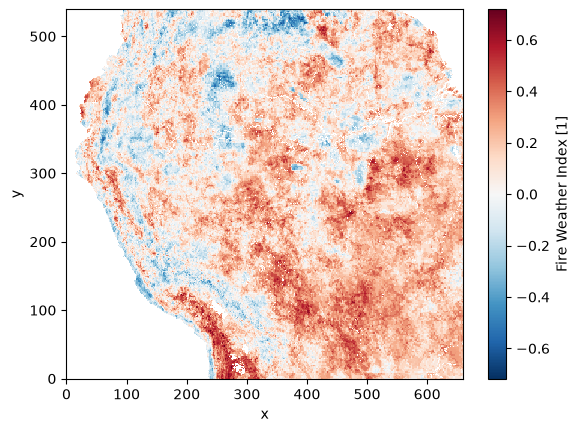

In [38]:
rps_fcst=sum_cat_brier.mean(dim='year', skipna=True)

mean_correction=correction_factor.mean(dim='year', skipna=True)

# Expected cumulative RPS for equally likely tercile outcomes.
rps_clim= 4.0 / 9.0 # <-- normalized category score

# Calculate RPSS from the two average scores.
rpss_d=(
    1 - rps_fcst / (rps_clim + mean_correction)
)

rpss_d.plot()

## Independently deriving `rps_clim`


In [49]:
year=2017

# Matching retrospective outcome, classified using retrospective thresholds.
obs_prob = observed_all.sel(year=year, drop=True)
obs_cdf = obs_prob.cumsum("category", skipna=False)

obs_cdf.sel(y= 200, x= 300) # <--- near normal category

<xarray.DataArray 'retro_fwi' (category: 3)> Size: 24B
array([0., 1., 1.])
Coordinates:
  * category  (category) int64 24B 0 1 2
    y         int64 8B 200
    x         int64 8B 300
    lat       float32 4B -10.98
    lon       float32 4B -66.97
Attributes:
    long_name:  Fire Weather Index
    units:      1

In [51]:
# Equal-probability climatological forecast.
clim_prob = xr.full_like(obs_prob, 1.0 / 3.0)
clim_cdf = clim_prob.cumsum("category", skipna=False)

clim_cdf.sel(y= 200, x= 300)

<xarray.DataArray 'retro_fwi' (category: 3)> Size: 24B
array([0.33333333, 0.66666667, 1.        ])
Coordinates:
  * category  (category) int64 24B 0 1 2
    y         int64 8B 200
    x         int64 8B 300
    lat       float32 4B -10.98
    lon       float32 4B -66.97
Attributes:
    long_name:  Fire Weather Index
    units:      1

In [53]:
rps_clim_year = (
    (clim_cdf - obs_cdf) ** 2
).sum("category", skipna=False)#.where(valid)

rps_clim_year

<xarray.DataArray 'retro_fwi' (y: 540, x: 660)> Size: 3MB
array([[       nan,        nan,        nan, ..., 0.55555556, 0.55555556,
        0.55555556],
       [       nan,        nan,        nan, ..., 0.55555556, 0.55555556,
        0.55555556],
       [       nan,        nan,        nan, ..., 0.55555556, 0.55555556,
        0.55555556],
       ...,
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan]], shape=(540, 660))
Coordinates:
  * y        (y) int64 4kB 0 1 2 3 4 5 6 7 8 ... 532 533 534 535 536 537 538 539
  * x        (x) int64 5kB 0 1 2 3 4 5 6 7 8 ... 652 653 654 655 656 657 658 659
    lat      (y, x) float32 1MB -20.98 -20.98 -20.98 ... 5.975 5.975 5.975
    lon      (y, x) float32 1MB -81.97 -81.93 -81.88 ... -49.12 -49.08 -49.03
Attributes:
    long_name:  Fire Weather Index
    units:      1

In [54]:
rps_clim_year.sel(y= 200, x= 300)

<xarray.DataArray 'retro_fwi' ()> Size: 8B
array(0.22222222)
Coordinates:
    y        int64 8B 200
    x        int64 8B 300
    lat      float32 4B -10.98
    lon      float32 4B -66.97
Attributes:
    long_name:  Fire Weather Index
    units:      1

In [59]:
annual_rps_clim=[]

for year in range(2001, 2024+1):

    # Matching retrospective outcome, classified using retrospective thresholds.
    obs_prob = observed_all.sel(year=year, drop=True)
    obs_cdf = obs_prob.cumsum("category", skipna=False)

    # Equal-probability climatological forecast.
    clim_prob = xr.full_like(obs_prob, 1.0 / 3.0)
    clim_cdf = clim_prob.cumsum("category", skipna=False)

    rps_clim_year = (
        (clim_cdf - obs_cdf) ** 2
    ).sum("category", skipna=False)#.where(valid)

    annual_rps_clim.append(rps_clim_year)



In [64]:
annual_rps_clim=xr.concat(annual_rps_clim, dim='year')

rps_clim=annual_rps_clim.mean(dim='year', skipna=True)

rps_clim.sel(y= 200, x= 300)

<xarray.DataArray 'retro_fwi' ()> Size: 8B
array(0.44444444)
Coordinates:
    y        int64 8B 200
    x        int64 8B 300
    lat      float32 4B -10.98
    lon      float32 4B -66.97
Attributes:
    long_name:  Fire Weather Index
    units:      1